# BRUMA · 02 — Evaluación del modelo y explicabilidad

Lee los artefactos de `scripts/train.py`. Todas las cifras son **fuera de muestra**: cada año de 2024-2025 se predijo con un modelo entrenado solo con datos anteriores; los hiperparámetros y el umbral de alerta se eligieron con 2022-2023.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from bruma import config
IMG = ROOT / "docs" / "img"; IMG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
INK, ACCENT, TEAL, ORANGE, MUTED = "#1f2544", "#5b6cff", "#0f9f8f", "#f97316", "#8a93b5"
daily = pd.read_parquet(ROOT / "data/processed/daily_pm25.parquet")
hourly = pd.read_parquet(ROOT / "data/processed/hourly_pm25.parquet")
weather = pd.read_parquet(ROOT / "data/processed/daily_weather.parquet")
stations = pd.read_csv(ROOT / "data/processed/stations.csv")
names = dict(zip(stations.station, stations.nombre))
REF = [29493, 29509, 29511, 31379, 31854, 31856]  # estaciones con serie 2020-2025 consistente

import lightgbm as lgb
m = json.loads((ROOT / "artifacts/metrics.json").read_text(encoding="utf-8"))
preds = pd.read_parquet(ROOT / "artifacts/predictions.parquet")
shap_df = pd.read_parquet(ROOT / "artifacts/shap.parquet")
feats = pd.read_parquet(ROOT / "artifacts/features.parquet")

## 1. Tabla de métricas vs líneas base (2024-2025)

In [2]:
rows = []
for h, per in m["evaluacion"].items():
    for name, v in per["2024-2025"]["puntual"].items():
        rows.append({"horizonte": h.replace("h", "") + " día(s)", "modelo": name, **{k: round(x, 3) for k, x in v.items()}})
tbl = pd.DataFrame(rows).set_index(["horizonte", "modelo"])
tbl

MAE   RMSE  sesgo  \
horizonte modelo                                                               
1 día(s)  LightGBM (BRUMA)                               2.688  3.517  0.064   
          LightGBM + meteorología ERA5 del día objetivo  2.654  3.484  0.086   
          Regresión Ridge                                2.700  3.564  0.028   
          Persistencia (hoy = mañana)                    3.230  4.275  0.002   
          Estacional semanal                             4.370  6.060 -0.010   
          Climatología estación-mes                      4.895  6.403  1.420   
2 día(s)  LightGBM (BRUMA)                               3.188  4.197  0.458   
          LightGBM + meteorología ERA5 del día objetivo  3.214  4.279  0.215   
          Regresión Ridge                                3.318  4.375  0.599   
          Persistencia (hoy = mañana)                    4.006  5.209  0.011   
          Estacional semanal                             4.415  6.099 -0.010   
          Climatología estación-mes                      4.895  6.402  1.421   
3 día(s)  LightGBM (BRUMA)                               3.370  4.521  0.340   
          LightGBM + meteorología ERA5 del día objetivo  3.433  4.643  0.149   
          Regresión Ridge                                3.536  4.669  0.716   
          Persistencia (hoy = mañana)                    4.339  5.624  0.016   
          Estacional semanal                             4.434  6.108 -0.011   
          Climatología estación-mes                      4.895  6.402  1.422   

                                                            R2  \
horizonte modelo                                                 
1 día(s)  LightGBM (BRUMA)                               0.755   
          LightGBM + meteorología ERA5 del día objetivo  0.760   
          Regresión Ridge                                0.749   
          Persistencia (hoy = mañana)                    0.638   
          Estacional semanal                             0.274   
          Climatología estación-mes                      0.189   
2 día(s)  LightGBM (BRUMA)                               0.652   
          LightGBM + meteorología ERA5 del día objetivo  0.638   
          Regresión Ridge                                0.621   
          Persistencia (hoy = mañana)                    0.463   
          Estacional semanal                             0.264   
          Climatología estación-mes                      0.189   
3 día(s)  LightGBM (BRUMA)                               0.596   
          LightGBM + meteorología ERA5 del día objetivo  0.574   
          Regresión Ridge                                0.569   
          Persistencia (hoy = mañana)                    0.374   
          Estacional semanal                             0.262   
          Climatología estación-mes                      0.189   

                                                         skill_vs_persistencia  
horizonte modelo                                                                
1 día(s)  LightGBM (BRUMA)                                               0.168  
          LightGBM + meteorología ERA5 del día objetivo                  0.178  
          Regresión Ridge                                                0.164  
          Persistencia (hoy = mañana)                                    0.000  
          Estacional semanal                                            -0.353  
          Climatología estación-mes                                     -0.516  
2 día(s)  LightGBM (BRUMA)                                               0.204  
          LightGBM + meteorología ERA5 del día objetivo                  0.198  
          Regresión Ridge                                                0.172  
          Persistencia (hoy = mañana)                                    0.000  
          Estacional semanal                                            -0.102  
          Climatología estación-mes                                     -0.222  
3 d

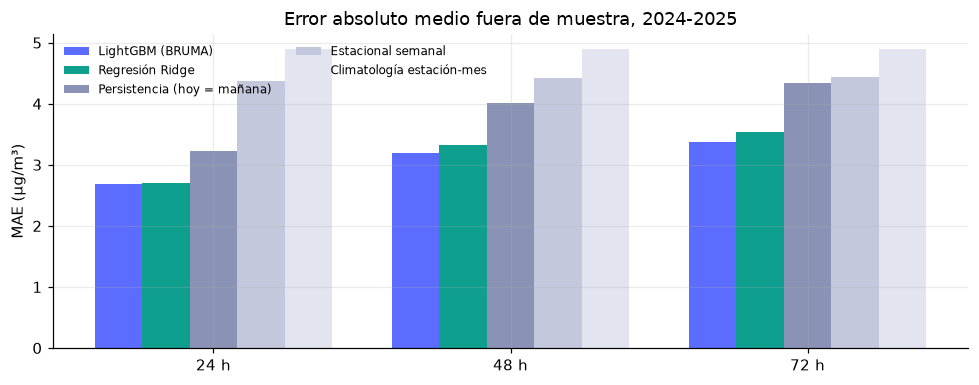

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
pv = tbl["MAE"].unstack(0)
order = ["LightGBM (BRUMA)", "Regresión Ridge", "Persistencia (hoy = mañana)", "Estacional semanal", "Climatología estación-mes"]
pv = pv.loc[order]
x = np.arange(len(pv.columns)); w = .16
cols = [ACCENT, TEAL, MUTED, "#c3c8dc", "#e2e5ef"]
for i, (name, r) in enumerate(pv.iterrows()):
    ax.bar(x + (i - 2) * w, r.values, w, label=name, color=cols[i])
ax.set_xticks(x, ["24 h", "48 h", "72 h"]); ax.set_ylabel("MAE (µg/m³)")
ax.set_title("Error absoluto medio fuera de muestra, 2024-2025"); ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(IMG / "metricas.png", dpi=130, bbox_inches="tight")

LightGBM reduce el error entre 17 % y 22 % frente a la persistencia. Una regresión Ridge con las mismas variables queda cerca a 24 h: la mayor parte de la señal es lineal (la contaminación de hoy). La ventaja del modelo de árboles crece con el horizonte.

### Por año y por temporada

In [4]:
pd.DataFrame({f"{h} · {y}": {"MAE BRUMA": v["puntual"]["LightGBM (BRUMA)"]["MAE"], "MAE persistencia": v["puntual"]["Persistencia (hoy = mañana)"]["MAE"],
   "MAE feb-abr": v["MAE_feb_abr"], "MAE resto del año": v["MAE_resto"], "días naranja": v["alerta_naranja"]["n_dias_naranja"]}
   for h, per in m["evaluacion"].items() for y, v in per.items() if y != "2024-2025"}).T.round(2)

,MAE BRUMA,MAE persistencia,MAE feb-abr,MAE resto del año,días naranja
h1 · 2024,2.91,3.53,3.88,2.57,210.0
h1 · 2025,2.46,2.93,2.65,2.40,8.0
h2 · 2024,3.62,4.46,5.46,2.96,210.0
h2 · 2025,2.76,3.55,3.22,2.60,8.0
h3 · 2024,3.85,4.87,6.05,3.07,210.0
h3 · 2025,2.88,3.81,3.45,2.69,8.0


El error se duplica en la temporada feb-abr: los episodios son justamente lo más difícil de pronosticar.

### Ablación: meteorología del día objetivo

La variante con meteorología ERA5 del día pronosticado simula un pronóstico del tiempo perfecto (no existe al emitir).

In [5]:
alt = "LightGBM + meteorología ERA5 del día objetivo"
pd.DataFrame({h: {"ajuste 2022-23 BRUMA": m["ajuste"][h]["LightGBM (BRUMA)"]["MAE"], "ajuste 2022-23 +ERA5": m["ajuste"][h][alt]["MAE"],
                  "eval 2024-25 BRUMA": m["evaluacion"][h]["2024-2025"]["puntual"]["LightGBM (BRUMA)"]["MAE"],
                  "eval 2024-25 +ERA5": m["evaluacion"][h]["2024-2025"]["puntual"][alt]["MAE"]} for h in m["evaluacion"]}).round(3)

,h1,h2,h3
ajuste 2022-23 BRUMA,2.836,3.347,3.445
ajuste 2022-23 +ERA5,2.709,3.187,3.308
eval 2024-25 BRUMA,2.688,3.188,3.370
eval 2024-25 +ERA5,2.654,3.214,3.433


Con información meteorológica *perfecta* el modelo mejora ~4-5 % en 2022-2023, pero en 2024-2025 la ganancia desaparece (+1 % a 24 h, peor a 48-72 h). Conclusión honesta: con un solo punto de reanálisis no se gana una ventaja estable, y el modelo operativo no la usa.

## 2. Incertidumbre: cuantiles + predicción conformal

In [6]:
cov = pd.DataFrame({h: {"cobertura cruda": per["2024-2025"]["intervalo_crudo"]["cobertura_80"],
                         "cobertura conformal": per["2024-2025"]["intervalo_conformal"]["cobertura_80"],
                         "ancho crudo": per["2024-2025"]["intervalo_crudo"]["ancho_medio"],
                         "ancho conformal": per["2024-2025"]["intervalo_conformal"]["ancho_medio"]} for h, per in m["evaluacion"].items()})
cov.round(3)

,h1,h2,h3
cobertura cruda,0.679,0.673,0.683
cobertura conformal,0.822,0.834,0.842
ancho crudo,6.773,7.761,8.452
ancho conformal,9.015,10.690,11.596


In [7]:
p1 = preds[preds.horizon == 1].copy(); p1["temporada"] = np.where(p1.target_date.dt.month.isin([2,3,4]), "feb-abr", "resto")
p1["dentro"] = (p1.y >= p1.q10) & (p1.y <= p1.q90)
p1.groupby("temporada").dentro.mean().round(3).to_frame("cobertura 80 % (24 h)")

,cobertura 80 % (24 h)
temporada,
feb-abr,0.769
resto,0.840


Los cuantiles de LightGBM cubren solo ~67 % (bandas demasiado estrechas). La corrección conformal (CQR), estimada solo con residuos de años anteriores, lleva la cobertura a ~82-84 %. En feb-abr la cobertura es menor: la incertidumbre no es homogénea.

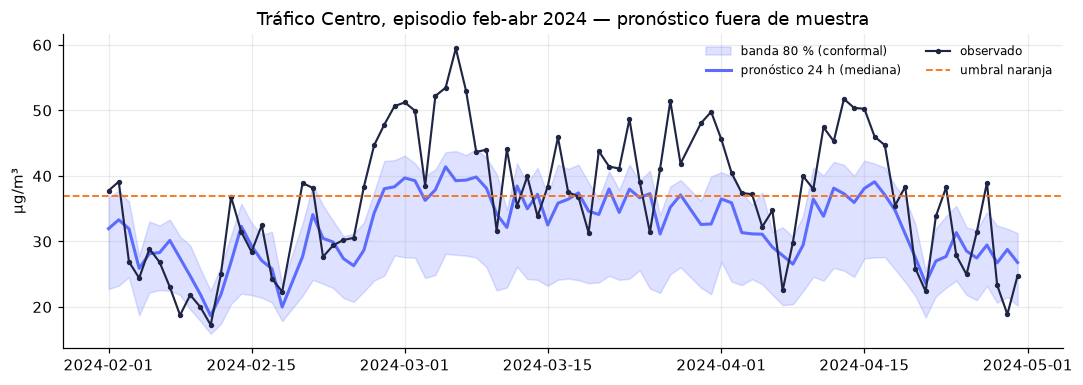

In [8]:
s = preds[(preds.horizon == 1) & (preds.station == 29509)].set_index("target_date").sort_index()["2024-02-01":"2024-04-30"]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.fill_between(s.index, s.q10, s.q90, color=ACCENT, alpha=.2, label="banda 80 % (conformal)")
ax.plot(s.index, s.q50, color=ACCENT, lw=2, label="pronóstico 24 h (mediana)")
ax.plot(s.index, s.y, color=INK, lw=1.4, marker="o", ms=2.5, label="observado")
ax.axhline(config.ICA_NARANJA, color=ORANGE, ls="--", lw=1.2, label="umbral naranja")
ax.set_title("Tráfico Centro, episodio feb-abr 2024 — pronóstico fuera de muestra"); ax.set_ylabel("µg/m³")
ax.legend(frameon=False, ncol=2, fontsize=8)
fig.tight_layout(); fig.savefig(IMG / "pronostico_episodio.png", dpi=130, bbox_inches="tight")

En los picos el modelo **subestima** sistemáticamente: es el comportamiento esperado de un pronóstico mediano que regresa hacia la media.

## 3. Probabilidad de nivel naranja

In [9]:
pd.DataFrame({h: {k: v for k, v in per["2024-2025"]["alerta_naranja"].items()} for h, per in m["evaluacion"].items()}).T

,n_dias_naranja,n,brier,brier_skill_vs_climatologia,roc_auc,pr_auc,tasa_base,umbral,verdaderos_positivos,falsas_alarmas,eventos_perdidos,recall,precision
h1,218.0,13187.0,0.012554,0.231015,0.978132,0.471739,0.016531,0.325,68.0,68.0,150.0,0.311927,0.500000
h2,218.0,13187.0,0.016384,-0.003625,0.940206,0.189918,0.016531,0.075,50.0,147.0,168.0,0.229358,0.253807
h3,218.0,13187.0,0.015398,0.056771,0.938398,0.212163,0.016531,0.075,56.0,159.0,162.0,0.256881,0.260465


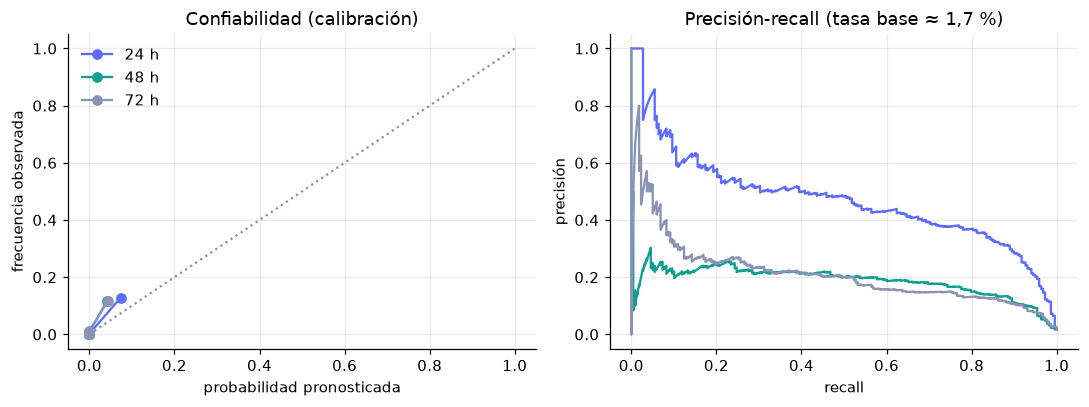

In [10]:
from sklearn.calibration import calibration_curve
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for h, c in zip((1, 2, 3), (ACCENT, TEAL, MUTED)):
    p = preds[preds.horizon == h]; yb = (p.y > config.ICA_NARANJA).astype(int)
    fr, mp = calibration_curve(yb, p.p_naranja, n_bins=8, strategy="quantile")
    axes[0].plot(mp, fr, marker="o", color=c, label=f"{h*24} h")
    from sklearn.metrics import precision_recall_curve
    pr, rc, _ = precision_recall_curve(yb, p.p_naranja); axes[1].plot(rc, pr, color=c, label=f"{h*24} h")
axes[0].plot([0, 1], [0, 1], color=MUTED, ls=":"); axes[0].set_xlabel("probabilidad pronosticada"); axes[0].set_ylabel("frecuencia observada")
axes[0].set_title("Confiabilidad (calibración)"); axes[0].legend(frameon=False)
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precisión"); axes[1].set_title("Precisión-recall (tasa base ≈ 1,7 %)")
fig.tight_layout(); fig.savefig(IMG / "alerta.png", dpi=130, bbox_inches="tight")

Con solo 218 estación-días en naranja en 2024-2025 (210 en 2024 y 8 en 2025) estas cifras son ruidosas. A 24 h el modelo ordena bien el riesgo (ROC-AUC ≈ 0,98, PR-AUC ≈ 0,47 frente a una tasa base de 1,7 %); a 48-72 h la utilidad cae mucho.

## 4. Explicabilidad con SHAP

C:\Users\johncastrillon\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


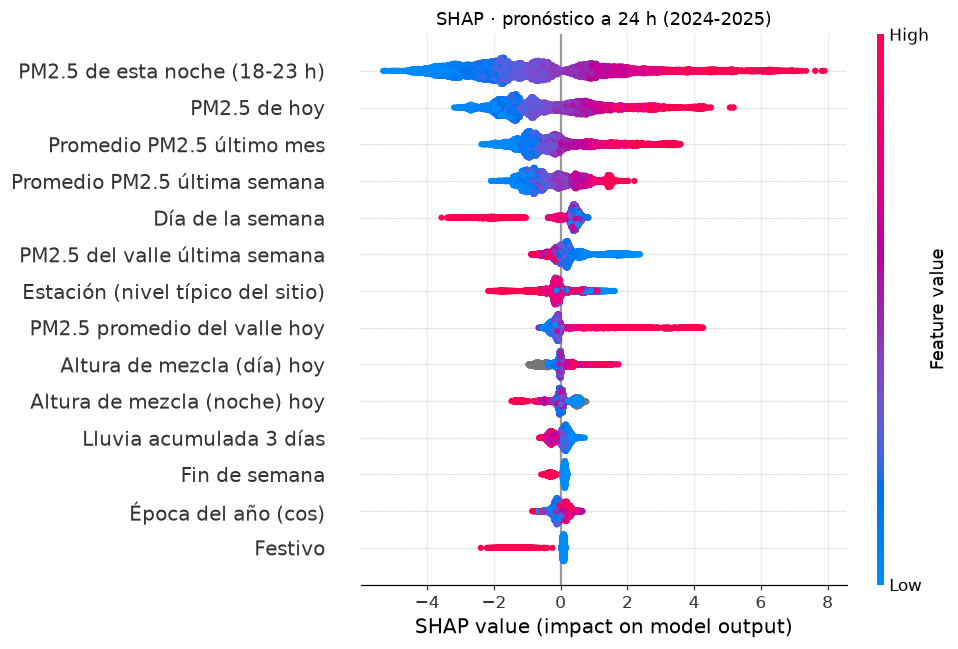

In [11]:
import shap
h = 1
mask = (feats.horizon == h).to_numpy()
cols = [c for c in shap_df.columns if c not in ("horizon", "base_value")]
from bruma.features import FEATURE_LABELS
X = feats.loc[mask, cols].copy(); X["station"] = X["station"].astype(float)
sv = shap_df.loc[mask, cols].to_numpy()
plt.figure()
shap.summary_plot(sv, X.rename(columns=FEATURE_LABELS), max_display=14, show=False, plot_size=(9, 6))
plt.title("SHAP · pronóstico a 24 h (2024-2025)"); plt.tight_layout()
plt.savefig(IMG / "shap_resumen.png", dpi=130, bbox_inches="tight")

In [12]:
imp = json.loads((ROOT / "artifacts/importance.json").read_text(encoding="utf-8"))
pd.DataFrame({h: pd.Series(v).rename(index=FEATURE_LABELS) for h, v in imp.items()}).sort_values("h1", ascending=False).head(12).round(2)

,h1,h2,h3
PM2.5 de esta noche (18-23 h),2.03,0.66,0.31
PM2.5 de hoy,1.31,0.47,0.21
Promedio PM2.5 último mes,0.90,1.55,1.76
Promedio PM2.5 última semana,0.72,1.63,1.68
Día de la semana,0.62,0.81,0.78
PM2.5 del valle última semana,0.39,0.40,0.36
Estación (nivel típico del sitio),0.33,0.46,0.48
PM2.5 promedio del valle hoy,0.32,0.16,0.22
Altura de mezcla (día) hoy,0.29,0.21,0.32
Altura de mezcla (noche) hoy,0.26,0.19,0.17


- A 24 h domina el **nivel de la noche anterior** (18-23 h) y el promedio del día: persistencia.
- A 48-72 h pesan más los promedios de 7 y 28 días y el **día de la semana** (menos tráfico el domingo).
- La meteorología del día de emisión (altura de mezcla, humedad, lluvia acumulada) aporta, pero en segundo plano.

Estas contribuciones explican **qué usa el modelo**, no qué causa la contaminación.